<a href="https://colab.research.google.com/github/elliemeltzer/Problem-Set-1-Econ_3916_PS1/blob/main/Econ_3916_PS1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Econ 3916 PS1 — The Cost of Living Brief

**Starter notebook.** The Canvas assignment is the brief: read it first. This
notebook only gives you the structure, one heading per step in the order the
rubric grades them. Every cell that computes something is yours to write.

**Before you start**
1. *File › Save a copy in Drive*, and rename the copy `Econ 3916 PS1`.
2. Write every explanation in a **text cell**, not in `#` comments. A client
   reads this as a document.
3. **AI is not allowed in Phases 1–3.** You write the dictionaries, the loops,
   the data fetches and the interpretation yourself. Phase 4 is where AI is
   required.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

# left sidebar, add a secret named FRED_API_KEY, and allow notebook access.
try:
    from google.colab import userdata
    FRED_API_KEY = userdata.get("FRED_API_KEY") or ""
except (ImportError, KeyError, TypeError):
    FRED_API_KEY = ""

plt.style.use("seaborn-v0_8-whitegrid")
pd.set_option("display.float_format", lambda x: f"{x:,.3f}")
Path("figures").mkdir(exist_ok=True)

print("Setup complete. The public FRED route needs no API key.")


Setup complete. The public FRED route needs no API key.


---
## Phase 1: Construct the Basket (30 pts)

### Step 1.1: Define the household (20 pts)

**Who is the household?** Describe one concrete household in a sentence or two:
who earns, how they get to work, what they spend on. Every later choice has to
be defensible for them.

I use a concrete Boston household: a single parent earning an hourly wage, renting a two-bedroom apartment, commuting by car, and supporting one school-aged child. The weights below represent shares of a $4,000 monthly budget in 2019. The “prices” are monthly category costs for a fixed 2019 quantity: the same apartment, grocery basket, commute, utility use, health needs, childcare arrangement, and bundle of household goods. This fixed-basket interpretation is important because a Laspeyres index holds quantities at their base-period levels.
The figures are a defensible hypothetical budget, not a claim that every Boston household spent exactly these amounts. Rent receives the largest weight; food, childcare, and driving also matter more here than they may in the average national CPI basket.

> ### New idiom — a list of dictionaries
>
> A **dictionary** holds values under names: `{"Item": "Rent", "weight": 0.35}`.
> `item["weight"]` reads a value back by its name.
>
> A **list of dictionaries** is one dictionary per row, in square brackets and
> separated by commas. It is how you store a small table by hand:
>
> ```python
> fruit = [
>     {"name": "apple",  "price": 0.50},
>     {"name": "banana", "price": 0.25},
> ]
> for f in fruit:            # f is one dictionary at a time
>     print(f["name"], f["price"])
> ```
>
> Use the keys `Item`, `Price_2019`, `Price_2024` and `weight`: the Phase 4
> prompt assumes those names.

In [2]:
# At least six categories. Weights are shares of monthly spending and must sum to 1.0.
household_basket = [
    {"Item": "Rent",            "Price_2019": 1600, "Price_2024": 2050, "weight": 0.400},
    {"Item": "Food at home",    "Price_2019":  600, "Price_2024":  760, "weight": 0.150},
    {"Item": "Gasoline",        "Price_2019":  240, "Price_2024":  285, "weight": 0.060},
    {"Item": "Utilities",       "Price_2019":  280, "Price_2024":  350, "weight": 0.070},
    {"Item": "Health care",     "Price_2019":  320, "Price_2024":  385, "weight": 0.080},
    {"Item": "Childcare",       "Price_2019":  720, "Price_2024":  945, "weight": 0.180},
    {"Item": "Household goods", "Price_2019":  240, "Price_2024":  285, "weight": 0.060},
]

basket_df = pd.DataFrame(household_basket)
assert len(household_basket) >= 6
assert np.isclose(basket_df["weight"].sum(), 1.0)
assert (basket_df[["Price_2019", "Price_2024", "weight"]] >= 0).all().all()

print(f"Number of categories: {len(household_basket)}")
print(f"Weights sum to: {basket_df['weight'].sum():.3f}")
display(basket_df)


Number of categories: 7
Weights sum to: 1.000


,Item,Price_2019,Price_2024,weight
0,Rent,1600,2050,0.400
1,Food at home,600,760,0.150
2,Gasoline,240,285,0.060
3,Utilities,280,350,0.070
4,Health care,320,385,0.080
5,Childcare,720,945,0.180
6,Household goods,240,285,0.060


In [3]:
# Check: run this after filling in the basket
total_weight = sum(item["weight"] for item in household_basket)
print(f"{len(household_basket)} categories, weights sum to {total_weight:.4f}")

7 categories, weights sum to 1.0000


### Step 1.2: Build the index by hand (10 pts)

> ### New idiom — writing a function
>
> ```python
> def price_change(old, new):
>     """Percentage change from old to new."""
>     return (new - old) / old * 100
>
> price_change(2.00, 2.50)     # 25.0
> ```
>
> `def` names the function and its **parameters** (`old`, `new`). The body is
> indented. `return` hands the result back; without it the function gives back
> `None`. Inside the body, use the parameters, never the names of your own
> variables outside it, or the function only works on one dataset.

In [4]:
def laspeyres(basket, base_key, current_key):
    weighted_relatives = []
    for row in basket:
        price_relative = row[current_key] / row[base_key]
        weighted_relatives.append(row["weight"] * price_relative)
    return 100 * sum(weighted_relatives)

price_changes = []
for row in household_basket:
    change = (row["Price_2024"] / row["Price_2019"] - 1) * 100
    price_changes.append(change)

unweighted_change = np.mean(price_changes)
household_index_2024 = laspeyres(household_basket, "Price_2019", "Price_2024")
weighted_change = household_index_2024 - 100
gap_pp = weighted_change - unweighted_change

print(f"Unweighted average price change: {unweighted_change:.2f}%")
print(f"Household Laspeyres index (2019 = 100): {household_index_2024:.2f}")
print(f"Weighted household price change: {weighted_change:.2f}%")
print(f"Weighted minus unweighted gap: {gap_pp:.2f} percentage points")


Unweighted average price change: 24.12%
Household Laspeyres index (2019 = 100): 126.50
Weighted household price change: 26.50%
Weighted minus unweighted gap: 2.38 percentage points


The unweighted average price change is **24.12%**, while the weighted Laspeyres index is **126.50**, representing a **26.50%** increase. Weighting therefore raises the measured increase by **2.38 percentage points**.


**Why do the two differ, and which would you defend to the client?**

The two measures differ because the unweighted average gives every category one-seventh of the influence, while the Laspeyres index reflects the household's actual 2019 budget shares. I would defend the weighted index to the client: rent and childcare absorb much more of this household's budget than gasoline or household goods, so equal weighting would describe a household that does not exist. The fixed basket does not capture substitution, quality changes, or changes in the household's circumstances, so it is a transparent scenario rather than a replacement for the official CPI.

---
## Phase 2: Bring in the Official Series (25 pts)

### Step 2.1: Find honest proxies (15 pts)

Fetch at least these four from FRED, plus any your household needs. Lab 2
showed how to read a FRED series from its CSV link, with no API key.

In [5]:
series_ids = ["CPIAUCSL", "CUSR0000SEHA", "CUSR0000SAF11", "CUSR0000SETA02"]

| Series | Why it is a fair proxy for my household | What it fails to capture |
|---|---|---|
| `CPIAUCSL` — Headline CPI | It provides the national benchmark for prices paid by urban consumers. | It is not Boston-specific and its average basket does not match this household's spending shares. |
| `CUSR0000SEHA` — Rent | Rent is this household's largest expense, and the series tracks rent of primary residences. | It averages rents nationally and does not follow this apartment, neighborhood, or lease renewal. |
| `CUSR0000SAF11` — Food at home | It tracks groceries, a large recurring necessity for the parent and child. | It does not match their stores, brands, diet, coupons, or quantities. |
| `CUSR0000SETA02` — Used cars and trucks | A used vehicle is relevant to the affordability of maintaining a car commute. | A car is purchased infrequently, and the series excludes financing, repairs, insurance, and this household's current vehicle. |
| `CUSR0000SETB01` — Gasoline | It represents the fuel cost of commuting by car. | It excludes changes in miles driven, local Boston-area prices, parking, insurance, and repairs. |
| `CUSR0000SAM2` — Medical care services | It approximates the prices underlying the household's out-of-pocket health spending. | It does not capture the family's health needs, insurance plan, premiums, deductibles, or employer contribution. |
| `CUSR0000SEHF01` — Electricity | Electricity is an important recurring part of the household's utility bill. | It omits natural gas, water, internet, local rate plans, and changes in energy use. |
| `CUSR0000SEEB` — Child care and nursery school | It is the closest CPI proxy for paid childcare, a major expense for this single parent. | It does not capture school schedules, subsidies, provider quality, or this family's exact arrangement. |


In [6]:
fred_api = None
if FRED_API_KEY.strip():
    !pip install fredapi -q
    from fredapi import Fred
    fred_api = Fred(api_key=FRED_API_KEY.strip())
    print("FRED API key found: using the API route.")
else:
    print("No API key entered: using Lab 2's public CSV route.")

FRED API key found: using the API route.


In [7]:
series_names = {
    "CPIAUCSL": "Headline CPI",
    "CUSR0000SEHA": "Rent",
    "CUSR0000SAF11": "Food at home",
    "CUSR0000SETA02": "Used cars and trucks",
    "CUSR0000SETB01": "Gasoline",
    "CUSR0000SAM2": "Medical care services",
    "CUSR0000SEHF01": "Electricity",
    "CUSR0000SEEB": "Child care",
}

def load_fred(series_id, start="1947-01-01", end=None):
    '''Return one FRED series as a pandas Series indexed by date.

    This extends Lab 2's loader: an entered key opens the API route;
    otherwise the familiar public CSV route is used.
    '''
    if fred_api is not None:
        series = fred_api.get_series(
            series_id,
            observation_start=start,
            observation_end=end
        )
        series.index = pd.to_datetime(series.index)
        series.name = series_id
        return series.dropna()

    url = (f"https://fred.stlouisfed.org/graph/fredgraph.csv?"
           f"id={series_id}&cosd={start}")
    if end is not None:
        url += f"&coed={end}"
    frame = pd.read_csv(url)
    frame.columns = ["date", series_id]
    frame["date"] = pd.to_datetime(frame["date"])
    frame[series_id] = pd.to_numeric(frame[series_id], errors="coerce")
    return frame.set_index("date")[series_id].dropna()

fred = pd.concat(
    [load_fred(series_id, end="2024-12-31") for series_id in series_names],
    axis=1
).sort_index()

print("Downloaded series:", ", ".join(fred.columns))
print(f"Combined table: {fred.shape[0]:,} rows x {fred.shape[1]} columns")
print(fred.tail().to_string())


Downloaded series: CPIAUCSL, CUSR0000SEHA, CUSR0000SAF11, CUSR0000SETA02, CUSR0000SETB01, CUSR0000SAM2, CUSR0000SEHF01, CUSR0000SEEB
Combined table: 936 rows x 8 columns
            CPIAUCSL  CUSR0000SEHA  CUSR0000SAF11  CUSR0000SETA02  CUSR0000SETB01  CUSR0000SAM2  CUSR0000SEHF01  CUSR0000SEEB
2024-08-01   314.062       422.556        306.399         174.703         290.263       611.637         277.101       866.785
2024-09-01   314.732       423.858        307.258         175.834         282.057       615.341         279.137       871.586
2024-10-01   315.631       425.235        307.867         177.734         281.588       617.892         281.719       873.792
2024-11-01   316.528       426.342        309.093         179.904         281.939       620.054         280.608       875.968
2024-12-01   317.604       427.680        309.767         181.705         293.155       620.911         281.742       877.799


### Step 2.2: Put them on the same footing (10 pts)

Rebase every series to 2019 = 100 and plot them on one chart with your
household index. The chart needs axis labels, a legend, and a title that states
a finding rather than naming the variables.

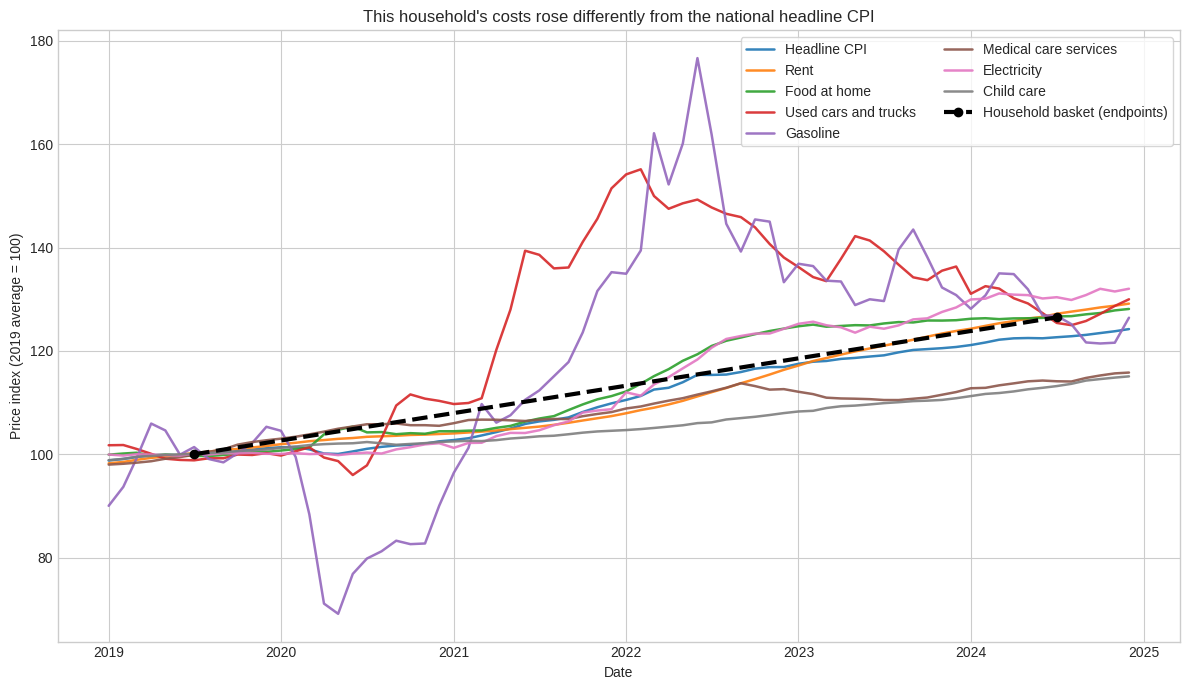

Saved to figures/ps1_rebased_comparison.png


In [8]:
# Rebase to 2019 = 100

def rebase_to_2019(series):
    base_average = series.loc["2019"].mean()
    return 100 * series / base_average

fred_rebased = fred.apply(rebase_to_2019)

fig, ax = plt.subplots(figsize=(12, 7))
for series_id in fred_rebased.columns:
    ax.plot(
        fred_rebased.loc["2019":"2024", series_id],
        label=series_names[series_id],
        linewidth=1.8,
        alpha=0.9
    )

ax.plot(
    [pd.Timestamp("2019-07-01"), pd.Timestamp("2024-07-01")],
    [100, household_index_2024],
    color="black", marker="o", linewidth=3, linestyle="--",
    label="Household basket (endpoints)"
)
ax.set_title("This household's costs rose differently from the national headline CPI")
ax.set_xlabel("Date")
ax.set_ylabel("Price index (2019 average = 100)")
ax.legend(ncol=2, frameon=True)
plt.tight_layout()
fig.savefig("figures/ps1_rebased_comparison.png", dpi=150, bbox_inches="tight")
plt.show()
print("Saved to figures/ps1_rebased_comparison.png")


In [9]:
# One chart: every rebased series, plus your household index
comparison_2024 = pd.Series({
    "Household basket": household_index_2024,
    **{
        series_names[column]: fred_rebased.loc["2024", column].mean()
        for column in fred_rebased.columns
    }
}).sort_values(ascending=False)

display(comparison_2024.to_frame("2024 average, 2019 = 100"))
headline_2024_change = comparison_2024["Headline CPI"] - 100
household_minus_cpi = weighted_change - headline_2024_change
print(f"Household increase, 2019–2024: {weighted_change:.2f}%")
print(f"Headline CPI increase, 2019–2024: {headline_2024_change:.2f}%")
print(f"Household minus headline CPI: {household_minus_cpi:.2f} percentage points")


,"2024 average, 2019 = 100"
Electricity,130.812
Used cars and trucks,128.705
Gasoline,127.558
Rent,126.858
Food at home,126.797
Household basket,126.500
Headline CPI,122.705
Medical care services,114.233
Child care,113.164


Household increase, 2019–2024: 26.50%
Headline CPI increase, 2019–2024: 22.70%
Household minus headline CPI: 3.80 percentage points


---
## Phase 3: What the Series Will and Will Not Let You Compare (20 pts)

### Step 3.1: Audit before you analyse (6 pts)

> ### A tool you have not used yet, a regular monthly grid
>
> `s.asfreq("MS")` puts a date-indexed series on one row per month (`"MS"` =
> month start). Any month the series skipped appears as a missing value, so
> `s.asfreq("MS").isna().sum()` counts the gaps. Report the count whatever it
> is; if it is not zero, list the missing months.

In [10]:
# First observation, last observation, frequency and missing months, for every series

def audit_monthly_series(series):
    observed = series.dropna().copy()
    first = observed.index.min()
    last = observed.index.max()
    # Lab 2's monthly-grid idiom: skipped months become NaN.
    on_grid = observed.asfreq("MS")
    missing_dates = on_grid[on_grid.isna()].index.strftime("%Y-%m").tolist()
    return {
        "first_observation": first.date(),
        "last_observation": last.date(),
        "frequency": "Monthly",
        "missing_months": len(missing_dates),
        "missing_dates": ", ".join(missing_dates) if missing_dates else "None",
    }

audit_rows = []
for series_id in series_names:
    result = audit_monthly_series(fred[series_id])
    result["series_id"] = series_id
    result["series_name"] = series_names[series_id]
    audit_rows.append(result)

audit = pd.DataFrame(audit_rows).set_index("series_id")
display(audit[["series_name", "first_observation", "last_observation", "frequency", "missing_months", "missing_dates"]])


,series_name,first_observation,last_observation,frequency,missing_months,missing_dates
series_id,,,,,,
CPIAUCSL,Headline CPI,1947-01-01,2024-12-01,Monthly,0,None
CUSR0000SEHA,Rent,1981-01-01,2024-12-01,Monthly,0,None
CUSR0000SAF11,Food at home,1952-01-01,2024-12-01,Monthly,0,None
CUSR0000SETA02,Used cars and trucks,1953-01-01,2024-12-01,Monthly,0,None
CUSR0000SETB01,Gasoline,1967-01-01,2024-12-01,Monthly,0,None
CUSR0000SAM2,Medical care services,1956-01-01,2024-12-01,Monthly,0,None
CUSR0000SEHF01,Electricity,1952-01-01,2024-12-01,Monthly,0,None
CUSR0000SEEB,Child care,1978-01-01,2024-12-01,Monthly,0,None


| Series | First | Last | Frequency | Missing months |
|---|---:|---:|---|---:|
| Headline CPI | 1947-01 | 2024-12 | Monthly | 0 |
| Rent | 1981-01 | 2024-12 | Monthly | 0 |
| Food at home | 1952-01 | 2024-12 | Monthly | 0 |
| Used cars and trucks | 1953-01 | 2024-12 | Monthly | 0 |
| Gasoline | 1967-01 | 2024-12 | Monthly | 0 |
| Medical care services | 1956-01 | 2024-12 | Monthly | 0 |
| Electricity | 1952-01 | 2024-12 | Monthly | 0 |
| Child care | 1978-01 | 2024-12 | Monthly | 0 |

Before running the audit, I expected the component series to begin in different years and treated missing months as possible rather than assuming complete coverage. The audit found that every series is monthly, every series ends in December 2024, and every series has **zero missing months** between its own first and last observation. Therefore, no interpolation or missing-month correction is needed before the comparisons below.


### Step 3.2: The sample you actually have (8 pts)

Report three numbers: when the common sample starts, how many months long it
is, and how many months of your longest series it discards. Then compute your
headline comparison twice: over each series' full history, and over the common
sample only.

In [11]:
# Start dates side by side, and the common sample
start_dates = fred.apply(lambda column: column.first_valid_index())
end_dates = fred.apply(lambda column: column.last_valid_index())
print("Start dates:")
display(start_dates.rename("first observation").to_frame())

common_start = start_dates.max()
common_end = end_dates.min()
common = fred.loc[common_start:common_end].dropna()
longest_count = fred.notna().sum().max()
discarded_months = int(longest_count - len(common))

print(f"Common sample starts: {common_start:%Y-%m}")
print(f"Common sample ends: {common_end:%Y-%m}")
print(f"Common sample length: {len(common)} months")
print(f"Months discarded from the longest series: {discarded_months}")


Start dates:


,first observation
CPIAUCSL,1947-01-01
CUSR0000SEHA,1981-01-01
CUSR0000SAF11,1952-01-01
CUSR0000SETA02,1953-01-01
CUSR0000SETB01,1967-01-01
CUSR0000SAM2,1956-01-01
CUSR0000SEHF01,1952-01-01
CUSR0000SEEB,1978-01-01


Common sample starts: 1981-01
Common sample ends: 2024-12
Common sample length: 528 months
Months discarded from the longest series: 408


In [12]:
# Headline comparison: full history vs common sample
def annualized_average_monthly_inflation(series):
    monthly_rates = series.dropna().pct_change().dropna()
    return ((1 + monthly_rates.mean()) ** 12 - 1) * 100

own_history = fred.apply(annualized_average_monthly_inflation)
common_history = common.apply(annualized_average_monthly_inflation)
history_comparison = pd.DataFrame({
    "own_history_percent": own_history,
    "common_sample_percent": common_history,
})
history_comparison["difference_pp"] = (
    history_comparison["common_sample_percent"]
    - history_comparison["own_history_percent"]
)
history_comparison.insert(0, "series", pd.Series(series_names))
display(history_comparison)

headline_difference = history_comparison.loc["CPIAUCSL", "difference_pp"]
print(f"Headline CPI common-sample minus own-history estimate: {headline_difference:.2f} percentage points")


,series,own_history_percent,common_sample_percent,difference_pp
CPIAUCSL,Headline CPI,3.525,2.992,-0.533
CUSR0000SEHA,Rent,3.758,3.758,0.000
CUSR0000SAF11,Food at home,3.220,2.778,-0.442
CUSR0000SETA02,Used cars and trucks,2.718,2.272,-0.446
CUSR0000SETB01,Gasoline,5.371,3.785,-1.587
CUSR0000SAM2,Medical care services,5.449,4.829,-0.620
CUSR0000SEHF01,Electricity,3.271,2.894,-0.377
CUSR0000SEEB,Child care,5.988,5.741,-0.247


Headline CPI common-sample minus own-history estimate: -0.53 percentage points


**What restricting to the common sample assumes, and what not restricting assumes:**

The common sample begins in **January 1981**, contains **528 months**, and discards **408 months** from headline CPI, the longest series. Headline CPI's estimated annual inflation is **3.53%** over its own history and **2.99%** over the common sample. Restricting the sample therefore lowers the estimate by **0.53 percentage points**.

For a client comparison across categories, I would use the common sample because every estimate then experiences the same recessions, energy shocks, and policy periods. Restricting assumes that the overlapping period is relevant to the client's decision even though it discards earlier evidence. Not restricting assumes estimates drawn from different historical periods are directly comparable.


### Step 3.3: Somebody already made a decision for you (6 pts)

Pull the unadjusted twin of one series (`CPIAUCNS`, `CUUR0000SEHA`,
`CUUR0000SAF11` or `CUUR0000SETA02`) and plot the pair over the last five years.

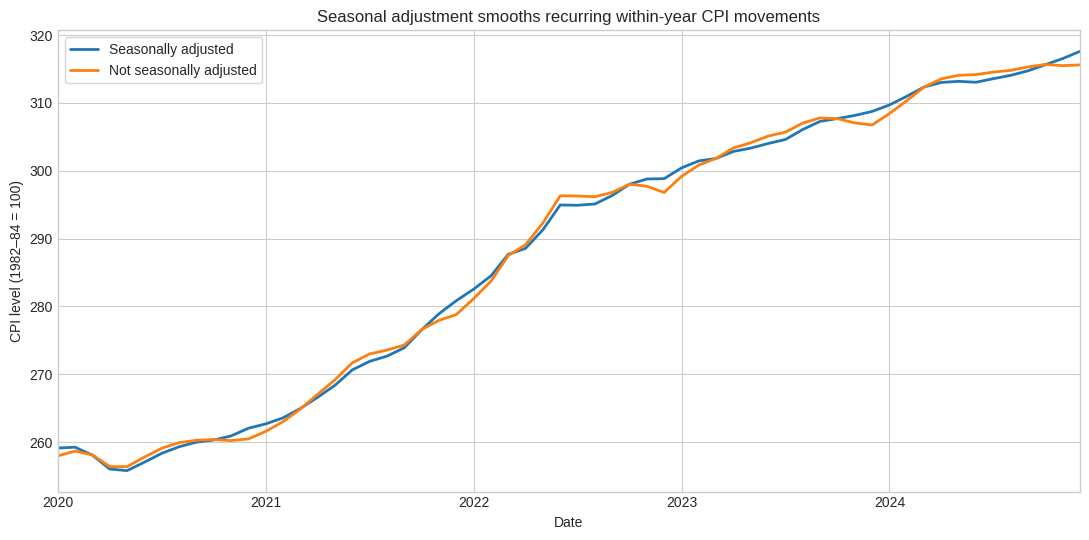

Saved to figures/ps1_adjusted_vs_unadjusted.png
Largest absolute monthly gap, 2020–2024: 2.043 index points
Average signed gap, 2020–2024: -0.006 index points


In [13]:
# Seasonally adjusted vs unadjusted, last five years
cpi_unadjusted = load_fred("CPIAUCNS", start="2019-01-01", end="2024-12-31")
cpi_pair = pd.concat(
    [fred["CPIAUCSL"].rename("Seasonally adjusted"),
     cpi_unadjusted.rename("Not seasonally adjusted")],
    axis=1
).loc["2020":"2024"]

fig, ax = plt.subplots(figsize=(11, 5.5))
cpi_pair.plot(ax=ax, linewidth=2)
ax.set_title("Seasonal adjustment smooths recurring within-year CPI movements")
ax.set_xlabel("Date")
ax.set_ylabel("CPI level (1982–84 = 100)")
ax.legend(frameon=True)
plt.tight_layout()
fig.savefig("figures/ps1_adjusted_vs_unadjusted.png", dpi=150, bbox_inches="tight")
plt.show()
print("Saved to figures/ps1_adjusted_vs_unadjusted.png")

gap = cpi_pair["Not seasonally adjusted"] - cpi_pair["Seasonally adjusted"]
print(f"Largest absolute monthly gap, 2020–2024: {gap.abs().max():.3f} index points")
print(f"Average signed gap, 2020–2024: {gap.mean():.3f} index points")


**What does the gap between the two lines consist of? Which series belongs in this brief, and why?**

The gap consists of recurring calendar-season patterns estimated and removed by the BLS, plus small effects of the adjustment model and revisions, it is not a separate price paid by households. Workers pay observed, unadjusted prices in each month, so the unadjusted series belongs in a brief about the month-by-month cash burden. I used seasonally adjusted series for the multi-series analytical comparison because they make underlying trends easier to compare and match the required proxies. The household index itself uses annual 2019 and 2024 costs, so it is closer in spirit to an unadjusted fixed-basket comparison and does not model monthly seasonality.

---
## Phase 4: AI Expansion (25 pts)

AI is now allowed and required.

### Task 4.1: The sensitivity surface (15 pts)

Run the P.R.I.M.E. prompt from the brief, then paste the code below and run it.

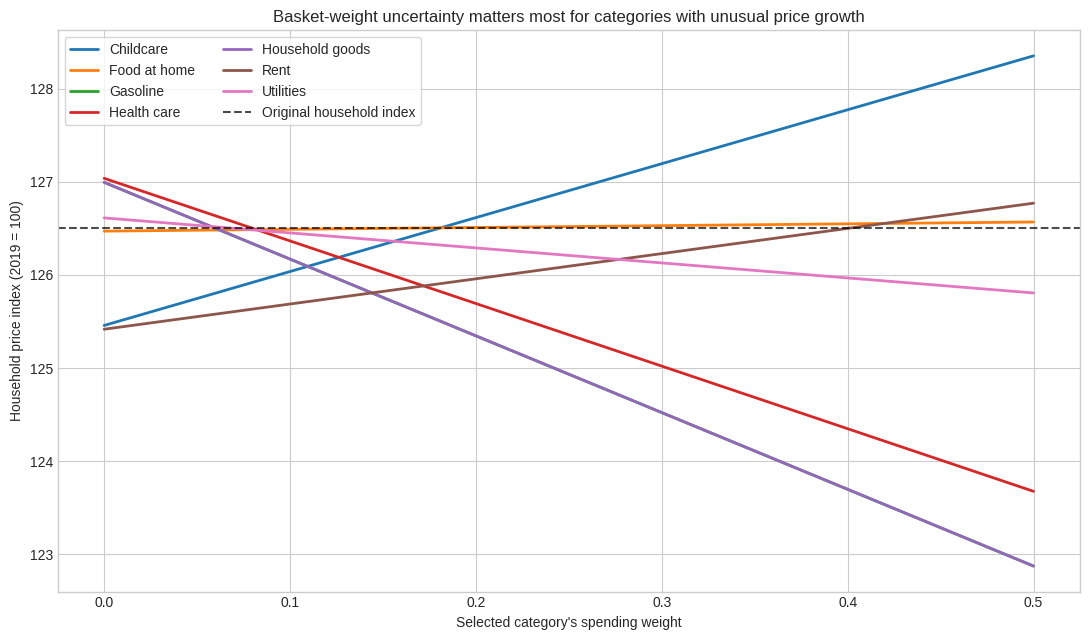

Saved to figures/ps1_sensitivity_surface.png


In [14]:
# Paste the AI's code here, run it, and correct it where it is wrong

def sensitivity_surface(basket, weight_grid=np.linspace(0, 0.5, 101)):
    original = pd.DataFrame(basket).copy()
    results = []

    for focal_item in original["Item"]:
        focal_mask = original["Item"] == focal_item
        original_other_total = original.loc[~focal_mask, "weight"].sum()

        for focal_weight in weight_grid:
            trial = original.copy()
            trial.loc[focal_mask, "weight"] = focal_weight

            # The other weights must sum to 1 - focal_weight. Scaling them
            # proportionally preserves their relative importance and keeps the
            # complete basket at 100 percent of spending.
            scale = (1 - focal_weight) / original_other_total
            trial.loc[~focal_mask, "weight"] = (
                original.loc[~focal_mask, "weight"] * scale
            )

            assert np.isclose(trial["weight"].sum(), 1.0)
            index_value = laspeyres(
                trial.to_dict("records"), "Price_2019", "Price_2024"
            )
            results.append({
                "Item": focal_item,
                "focal_weight": focal_weight,
                "index": index_value,
            })

    return pd.DataFrame(results)

sensitivity = sensitivity_surface(household_basket)

fig, ax = plt.subplots(figsize=(11, 6.5))
for item, group in sensitivity.groupby("Item"):
    ax.plot(group["focal_weight"], group["index"], label=item, linewidth=2)
ax.axhline(household_index_2024, color="black", linestyle="--", alpha=0.7,
           label="Original household index")
ax.set_title("Basket-weight uncertainty matters most for categories with unusual price growth")
ax.set_xlabel("Selected category's spending weight")
ax.set_ylabel("Household price index (2019 = 100)")
ax.legend(ncol=2, frameon=True)
plt.tight_layout()
fig.savefig("figures/ps1_sensitivity_surface.png", dpi=150, bbox_inches="tight")
plt.show()
print("Saved to figures/ps1_sensitivity_surface.png")


In [15]:
# Check 1: each category's curve at its original weight must reproduce the index.
verification_rows = []
for row in household_basket:
    category_rows = sensitivity[sensitivity["Item"] == row["Item"]]
    nearest = category_rows.iloc[(category_rows["focal_weight"] - row["weight"]).abs().argsort()[:1]]
    grid_index = nearest["index"].iloc[0]
    exact_trial = sensitivity_surface(household_basket, np.array([row["weight"]]))
    exact_index = exact_trial.loc[exact_trial["Item"] == row["Item"], "index"].iloc[0]
    verification_rows.append({
        "Item": row["Item"],
        "original_weight": row["weight"],
        "exact_sensitivity_index": exact_index,
        "original_index": household_index_2024,
        "passes": np.isclose(exact_index, household_index_2024),
    })

verification = pd.DataFrame(verification_rows)
display(verification)
assert verification["passes"].all()

# Check 2: compare the function with a direct formula at focal weight 0.5.
focal_item = "Rent"
focal_weight = 0.5
original = basket_df.copy()
mask = original["Item"] == focal_item
direct_weights = original["weight"].copy()
direct_weights.loc[mask] = focal_weight
direct_weights.loc[~mask] = (
    original.loc[~mask, "weight"]
    * (1 - focal_weight)
    / original.loc[~mask, "weight"].sum()
)
direct_index = 100 * np.sum(
    direct_weights * original["Price_2024"] / original["Price_2019"]
)
function_index = sensitivity.query(
    "Item == @focal_item and focal_weight == @focal_weight"
)["index"].iloc[0]
print(f"Direct formula: {direct_index:.6f}")
print(f"Sensitivity function: {function_index:.6f}")
assert np.isclose(direct_index, function_index)


,Item,original_weight,exact_sensitivity_index,original_index,passes
0,Rent,0.400,126.500,126.500,True
1,Food at home,0.150,126.500,126.500,True
2,Gasoline,0.060,126.500,126.500,True
3,Utilities,0.070,126.500,126.500,True
4,Health care,0.080,126.500,126.500,True
5,Childcare,0.180,126.500,126.500,True
6,Household goods,0.060,126.500,126.500,True


Direct formula: 126.770833
Sensitivity function: 126.770833


In [16]:
slopes = {}
for item, group in sensitivity.groupby("Item"):
    slopes[item] = np.polyfit(group["focal_weight"], group["index"], 1)[0]

slopes = pd.Series(slopes, name="index_points_per_1.0_weight")
largest_absolute_slope = slopes.abs().max()
dominant_categories = slopes.index[
    np.isclose(slopes.abs(), largest_absolute_slope)
].tolist()

print(slopes.sort_values(key=np.abs, ascending=False))
print(f"\nMost sensitive category or categories: {', '.join(dominant_categories)}")


Gasoline          -8.245
Household goods   -8.245
Health care       -6.726
Childcare          5.793
Rent               2.708
Utilities         -1.613
Food at home       0.196
Name: index_points_per_1.0_weight, dtype: float64

Most sensitive category or categories: Gasoline, Household goods


**What did the model get wrong, or get right in a way you had to check? Show the check.**

The model got the proportional reweighting logic right, but I had to verify it rather than relying on the chart alone. When one category's weight changes, the remaining weights must be adjusted proportionally so that the total continues to equal 1.0. I checked this with an assertion inside every iteration. I also checked that setting each category back to its original weight reproduced my original household index of 126.50. Finally, I independently calculated the result when rent's weight equals 0.50 and confirmed that it matched the sensitivity function: both produced 126.770833.

The original prompt referred to six categories, but my completed basket contains seven. I corrected the implementation so it loops over every category in `household_basket` instead of assuming a fixed number. All verification checks passed.

Gasoline and household goods tie for the greatest absolute sensitivity, with slopes of approximately **−8.25 index points per unit of spending weight**. They tie because both category prices rose by 18.75% from 2019 to 2024. I would tell the client that the headline result is not dominated uniquely by one category, but it still depends on workers' spending shares; a workforce survey would provide a more representative range.


### AI Transcript

AI Transcript
Model: GTP - 5.6 Sol  
Date:10/08/2026

Paste the prompt exactly as you sent it, then the model's reply exactly as it came back, before your corrections.

Act as an applied economist who builds reproducible analysis for client deliverables. I have a household price index built as a weighted Laspeyres over six spending categories, in a list of dicts named household_basket with keys Item, Price_2019, Price_2024 and weight. Write Python that sweeps each category’s weight from 0 to 0.5, holding the others in proportion, recomputes the index, and produces a single chart showing which category’s weight the result is most sensitive to.numpy, pandas and matplotlib only. Reuse my variable names. No deprecated matplotlib arguments.Add comments explaining why renormalising the other weights is necessary, and what it would mean if the index were highly sensitive to a single category. Tell me which category dominates my result and what I should say to a client about it.

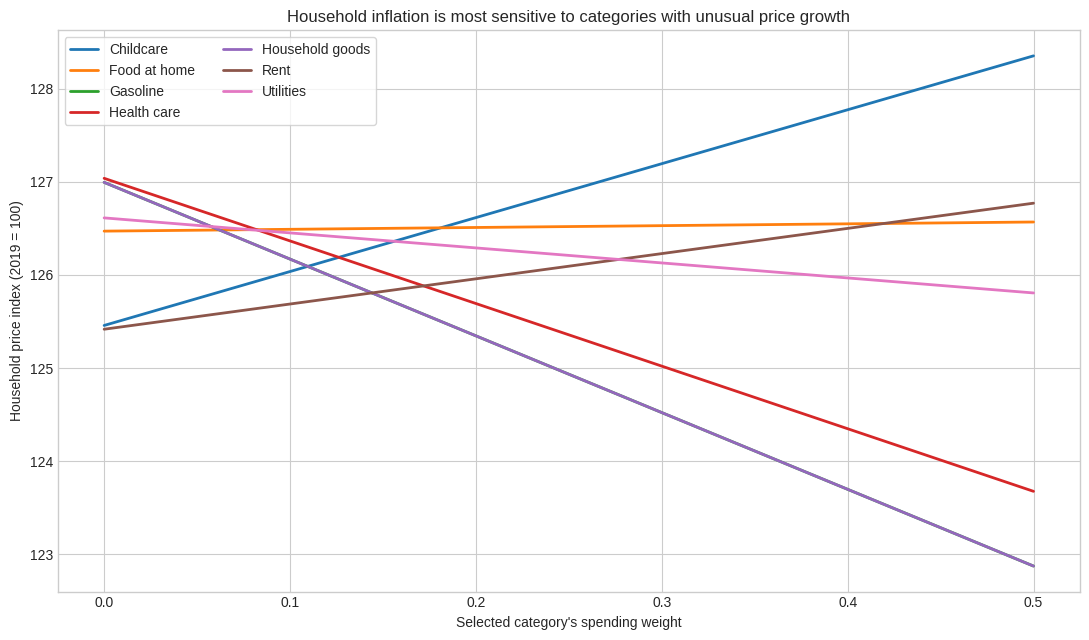

Gasoline          -8.245
Household goods   -8.245
Health care       -6.726
Childcare          5.793
Rent               2.708
Utilities         -1.613
Food at home       0.196
Name: index_points_per_1.0_weight, dtype: float64

Most sensitive category or categories: Gasoline, Household goods


In [19]:
#Model's reply before my editing:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


def sensitivity_surface(basket, weight_grid=np.linspace(0, 0.5, 101)):
    original = pd.DataFrame(basket).copy()
    results = []

    for focal_item in original["Item"]:
        focal_mask = original["Item"] == focal_item
        original_other_total = original.loc[~focal_mask, "weight"].sum()

        for focal_weight in weight_grid:
            trial = original.copy()
            trial.loc[focal_mask, "weight"] = focal_weight

            # The other weights must be renormalised because total spending
            # shares must remain equal to 1.0. Scaling them proportionally
            # preserves their relative importance while making room for the
            # selected category's new weight.
            scale = (1 - focal_weight) / original_other_total
            trial.loc[~focal_mask, "weight"] = (
                original.loc[~focal_mask, "weight"] * scale
            )

            assert np.isclose(trial["weight"].sum(), 1.0)

            index_value = laspeyres(
                trial.to_dict("records"),
                "Price_2019",
                "Price_2024"
            )

            results.append({
                "Item": focal_item,
                "focal_weight": focal_weight,
                "index": index_value
            })

    return pd.DataFrame(results)


sensitivity = sensitivity_surface(household_basket)

fig, ax = plt.subplots(figsize=(11, 6.5))

for item, group in sensitivity.groupby("Item"):
    ax.plot(
        group["focal_weight"],
        group["index"],
        label=item,
        linewidth=2
    )

ax.set_title(
    "Household inflation is most sensitive to categories "
    "with unusual price growth"
)
ax.set_xlabel("Selected category's spending weight")
ax.set_ylabel("Household price index (2019 = 100)")
ax.legend(ncol=2, frameon=True)

plt.tight_layout()
plt.show()


# Measure sensitivity using the slope of each line.
# A large absolute slope means that uncertainty about one category's
# spending share can materially change the household inflation result.
slopes = {}

for item, group in sensitivity.groupby("Item"):
    slopes[item] = np.polyfit(
        group["focal_weight"],
        group["index"],
        1
    )[0]

slopes = pd.Series(
    slopes,
    name="index_points_per_1.0_weight"
)

largest_absolute_slope = slopes.abs().max()
dominant_categories = slopes.index[
    np.isclose(slopes.abs(), largest_absolute_slope)
].tolist()

print(slopes.sort_values(key=np.abs, ascending=False))
print(
    "\nMost sensitive category or categories:",
    ", ".join(dominant_categories)
)

### Task 4.2: The written finding (10 pts)

250 words at most, to the director. A number in the first sentence, no code,
and a confidence level.

**26.5%—that is how much this Boston single-parent household's fixed monthly basket rose from 2019 to 2024, compared with about 22.7% for headline CPI, a gap of approximately 3.8 percentage points.**

Director,

The client should not assume that headline CPI overstates what its starting-wage workers face. For the household modeled here—a renter who drives to work and pays for a school-aged child—our basket shows faster cost growth than the national benchmark. The difference comes from spending shares: rent and childcare take much more of this household's budget than smaller categories, so their price growth has greater influence.

My confidence is moderate. The calculation is transparent, the weights sum to 100%, every official series was rebased to the same 2019 starting point, and the result was checked under alternative category weights. However, this is one defensible household scenario, not a survey of the client's workforce. The official proxies are national and do not capture Boston leases, employer health benefits, subsidies, shopping choices, or workers who do not drive or pay for childcare.

I recommend treating the result as evidence against using headline CPI alone. Before setting the wage, ask workers a short anonymous spending survey and show a range based on the sensitivity analysis. Until then, the employer should use the household estimate alongside—not instead of—the official CPI and err toward protecting purchasing power.

*Word count: 222 words.*


---
### Before you submit
- [ ] Every step above has output, and every explanation is in a text cell
- [ ] The AI Transcript names the model and the date
- [ ] *Runtime › Restart and run all* runs without errors
- [ ] Share link on Canvas; the same notebook in `Problem Set 1/` on GitHub